<a href="https://colab.research.google.com/github/sebastianvettel1212/Practical-Statistics-for-Data-Scientist-Books/blob/main/PracticalStatisticsChapter7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 7 — Unsupervised Learning

**Buku:** *Practical Statistics for Data Scientists* — Peter Bruce, Andrew Bruce & Peter Gedeck (O'Reilly)

Notebook ini berisi reproduksi kode, ringkasan, dan penjelasan teori **Bab 7** dalam Bahasa Indonesia.

## Daftar Isi
0. Persiapan
1. Principal Components Analysis (PCA)
2. K-Means Clustering
3. Hierarchical Clustering
4. Model-Based Clustering
5. Penskalaan dan Variabel Kategorikal
6. Ringkasan Bab

---

## Pengantar

**Unsupervised learning** adalah kelompok metode statistik yang **mengekstrak makna dari data tanpa melatih model pada data yang sudah diberi label** (tidak ada variabel hasil yang diketahui). Berbeda dengan prediksi (Bab 4 sampai 6), tujuannya bukan memprediksi suatu hasil, melainkan **mempelajari struktur data itu sendiri**. Ada dua tujuan utama:

1. **Reduksi dimensi**: merangkum banyak variabel menjadi sedikit variabel yang paling informatif (PCA, *correspondence analysis*).
2. **Clustering**: mengelompokkan rekaman yang mirip ke dalam kelompok (K-Means, *hierarchical*, *model-based*).

Unsupervised learning juga sering dipakai sebagai **langkah persiapan** untuk *supervised learning* (mis. membuat fitur baru dari klaster) dan sebagai **alat eksplorasi** (menemukan pola yang tidak terduga). Untuk dataset besar dengan banyak variabel, metode ini menjadi cara efisien untuk memahami data.

> **Catatan: *unsupervised* dan prediksi.** Klaster atau komponen yang dihasilkan **tidak punya "jawaban benar"** yang bisa dibandingkan. Kualitasnya dinilai dari **kegunaan dan keterjelasan** hasilnya (apakah klaster bermakna bagi bisnis?), bukan dari akurasi.

## 0. Persiapan

Data utama adalah **return harian saham S&P 500** (`sp500_data`) beserta sektornya, data pinjaman Lending Club (`loan_data`), dan data pembagian tugas rumah tangga (`housetasks`).

In [ ]:
import math
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import multivariate_normal

import prince
from adjustText import adjust_text

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 100

In [ ]:
# Lokasi dataset: folder lokal 'data/' atau, bila tidak ada, langsung dari GitHub repo resmi buku
DATA_DIR = Path('data')
RAW_URL = ('https://raw.githubusercontent.com/gedeck/'
           'practical-statistics-for-data-scientists/master/data/')

def path_data(nama_file):
    lokal = DATA_DIR / nama_file
    return lokal if lokal.exists() else RAW_URL + nama_file

SP500_DATA_CSV = path_data('sp500_data.csv.gz')
SP500_SECTORS_CSV = path_data('sp500_sectors.csv')
LOAN_DATA_CSV = path_data('loan_data.csv.gz')
HOUSE_TASKS_CSV = path_data('housetasks.csv')

sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)
print('sp500_px:', sp500_px.shape, '(hari perdagangan x simbol saham)')

sp500_px: (5647, 517) (hari perdagangan x simbol saham)


---
## 1. Principal Components Analysis (PCA)

Pada banyak dataset, variabel-variabel **saling berkorelasi**: ketika satu naik, yang lain cenderung ikut naik. **PCA** menggabungkan variabel numerik yang berkorelasi menjadi **sekumpulan kecil variabel baru yang tidak saling berkorelasi**, disebut **komponen utama (*principal components*)**, yang tetap menjelaskan sebagian besar variabilitas data. Teknik ini dikembangkan oleh **Karl Pearson (1901)**.

| Istilah | Penjelasan |
|---|---|
| **Principal component** | Kombinasi linear dari variabel prediktor |
| **Loadings** | Bobot yang mengubah prediktor asli menjadi komponen utama |
| **Screeplot** | Plot variansi yang dijelaskan tiap komponen, menampilkan kepentingan relatifnya |

### Gagasan
Komponen utama pertama $Z_1$ adalah kombinasi linear dari prediktor $X_1, \dots, X_p$:

$$Z_1 = w_{1,1} X_1 + w_{1,2} X_2 + \dots + w_{1,p} X_p$$

Bobot $w_{1,j}$ (*loadings*) dipilih sehingga $Z_1$ **menjelaskan variansi sebanyak mungkin**. Komponen kedua $Z_2$ dicari dengan syarat **tegak lurus (ortogonal)** terhadap $Z_1$ dan menjelaskan variansi sisa sebanyak mungkin, dan seterusnya. Hasilnya: komponen-komponen **tidak berkorelasi** satu sama lain, dan jumlah komponen sama dengan jumlah variabel asli, tetapi **beberapa komponen pertama biasanya sudah menangkap hampir seluruh informasi**.

Secara matematis, loadings adalah **vektor eigen** dari **matriks kovarians** data, dan variansi tiap komponen adalah **nilai eigen**-nya.

### Contoh sederhana: dua saham minyak
Kita ambil return harian **ExxonMobil (XOM)** dan **Chevron (CVX)**; keduanya berkorelasi tinggi karena sama-sama perusahaan minyak.

In [ ]:
oil_px = sp500_px[['XOM', 'CVX']]
print(oil_px.head())

pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns)
print('\nLoadings (baris = komponen):')
print(loadings)

                 XOM       CVX
1993-01-29 -0.016991  0.072921
1993-02-01  0.016991  0.102089
1993-02-02  0.084954  0.029168
1993-02-03  0.067964  0.058337
1993-02-04  0.034378  0.044272

Loadings (baris = komponen):
        XOM       CVX
0  0.664711  0.747101
1  0.747101 -0.664711


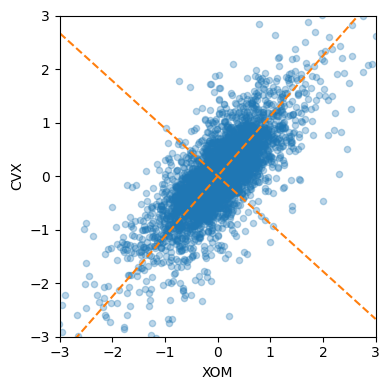

In [ ]:
# Gambar 7-1: komponen utama pada data XOM dan CVX (garis putus-putus = sumbu komponen)
def abline(slope, intercept, ax):
    # Hitung koordinat garis dari kemiringan dan intersep
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4, 4))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc[0, 'CVX'] / loadings.loc[0, 'XOM'], 0, ax),
        '--', color='C1')
ax.plot(*abline(loadings.loc[1, 'CVX'] / loadings.loc[1, 'XOM'], 0, ax),
        '--', color='C1')

plt.tight_layout()
plt.show()

**Interpretasi:** komponen pertama memiliki bobot **positif dan serupa** untuk XOM dan CVX (≈ 0,66 dan 0,75): ia menangkap **gerak bersama** kedua saham minyak (kenaikan/penurunan harga minyak secara umum). Komponen kedua memiliki **tanda berlawanan**: ia menangkap **selisih** antara keduanya. Garis putus-putus pada plot adalah **sumbu komponen**; sumbu pertama mengikuti arah sebaran terpanjang, sumbu kedua tegak lurus terhadapnya.

In [ ]:
# Verifikasi: loadings PCA = vektor eigen dari matriks kovarians; variansi komponen = nilai eigen
cov = np.cov(oil_px.values, rowvar=False)
eigval, eigvec = np.linalg.eigh(cov)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]

print('Nilai eigen (manual)   :', eigval.round(5))
print('Variansi (PCA sklearn) :', pcs.explained_variance_.round(5))
print('\nVektor eigen (kolom) vs loadings sklearn (tanda boleh terbalik):')
print(np.round(eigvec.T, 4))
print(np.round(pcs.components_, 4))

Nilai eigen (manual)   : [0.77822 0.09047]
Variansi (PCA sklearn) : [0.77822 0.09047]

Vektor eigen (kolom) vs loadings sklearn (tanda boleh terbalik):
[[ 0.6647  0.7471]
 [-0.7471  0.6647]]
[[ 0.6647  0.7471]
 [ 0.7471 -0.6647]]


**Interpretasi:** nilai eigen hasil perhitungan manual **identik** dengan variansi yang dilaporkan scikit-learn, dan vektor eigennya sama dengan loadings (tanda boleh terbalik karena arah sumbu tidak unik).

### Menginterpretasi Komponen Utama
Pada banyak variabel, kita biasanya menjaga **hanya beberapa komponen pertama**. **Screeplot** membantu memutuskan berapa komponen yang layak dipertahankan: cari titik "siku" (*elbow*) tempat tambahan variansi mulai mendatar.

Contoh: return harian 16 saham dari 4 sektor (teknologi, energi, keuangan, ritel) sejak 2011.

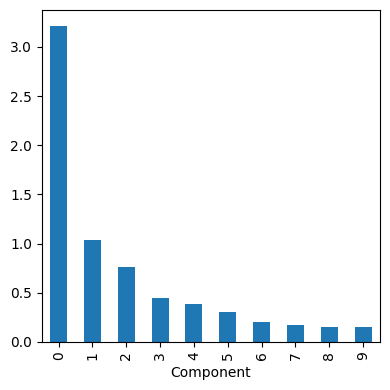

Proporsi variansi per komponen (5 pertama): [0.445 0.143 0.105 0.062 0.053]
Kumulatif 5 komponen pertama             : [0.445 0.588 0.693 0.755 0.809]


In [ ]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

# Gambar 7-2: screeplot
explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()

prop = sp_pca.explained_variance_ratio_
print('Proporsi variansi per komponen (5 pertama):', prop[:5].round(3))
print('Kumulatif 5 komponen pertama             :', prop[:5].cumsum().round(3))

**Interpretasi:** screeplot menunjukkan **komponen pertama menjelaskan variansi jauh lebih besar** daripada komponen lain (≈ 44,5% dari total), lalu variansi turun cepat dan mendatar. Lima komponen pertama sudah menjelaskan ≈ **80,9%** variansi, sehingga 16 saham dapat dirangkum dalam beberapa komponen saja.

In [ ]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :], columns=top_sp.columns)
print(loadings.round(3))

    AAPL    AXP    COP   COST   CSCO    CVX     HD   INTC    JPM   MSFT  \
0  0.301  0.246  0.262  0.274  0.064  0.444  0.208  0.077  0.196  0.105   
1  0.505  0.139 -0.174  0.416  0.032 -0.289  0.278  0.034  0.041  0.054   
2  0.787 -0.135  0.002 -0.466  0.008 -0.082 -0.166  0.004 -0.062 -0.016   
3 -0.121  0.062 -0.206  0.093  0.004 -0.578  0.163 -0.002  0.058 -0.013   
4 -0.112  0.597  0.006 -0.556  0.040 -0.109  0.185  0.072  0.385  0.077   

     SLB    TGT    USB    WFC    WMT    XOM  
0  0.482  0.149  0.116  0.146  0.122  0.318  
1 -0.472  0.228  0.055  0.047  0.223 -0.154  
2  0.195 -0.161 -0.049 -0.042 -0.176 -0.090  
3  0.681  0.110  0.017  0.019  0.058 -0.295  
4 -0.181  0.056  0.155  0.216 -0.092 -0.013  


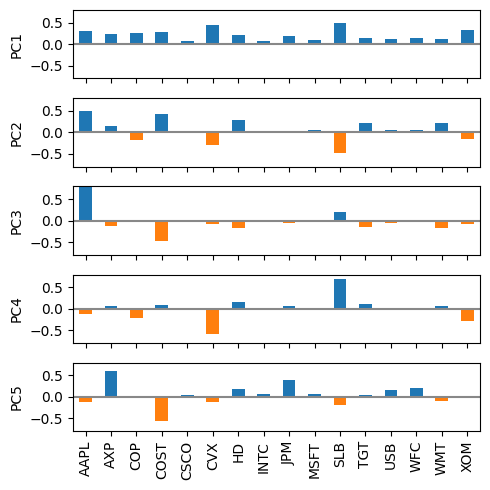

In [ ]:
# Gambar 7-3: loadings lima komponen pertama
maxPC = 1.01 * loadings.loc[0:5, :].abs().to_numpy().max()

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)

for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

**Interpretasi:**
- **PC1** memiliki bobot **positif untuk semua saham**: ia adalah **faktor pasar** keseluruhan (semua saham cenderung naik/turun bersama), dengan bobot terbesar pada saham energi (SLB, CVX, XOM, COP).
- **PC2** mengkontraskan **saham energi** (SLB, CVX, XOM, COP; bobot negatif) dengan saham **non-energi** seperti AAPL, COST, HD, dan TGT (bobot positif): perbedaan antara sektor energi dan sisanya.
- **PC3** didominasi **AAPL** (bobot positif besar) berlawanan dengan COST dan sebagian ritel; **PC4** mengkontraskan **SLB** dengan **CVX/XOM** (perbedaan di dalam sektor energi); **PC5** memisahkan saham **keuangan** (AXP, JPM, WFC, USB) dari COST.

Dengan demikian, PCA mengungkap **struktur sektoral** pasar saham (energi, keuangan, ritel, teknologi) tanpa diberi label sektor sama sekali.

### Correspondence Analysis
**Correspondence analysis** serupa PCA, tetapi untuk **data kategorikal** (tabel kontingensi/frekuensi). Tujuannya mengenali **hubungan antar kategori** dan memetakan baris dan kolom ke ruang 2D yang sama. Contoh: tabel frekuensi siapa yang mengerjakan tiap tugas rumah tangga (istri, bergantian, suami, bersama).

           Wife  Alternating  Husband  Jointly
Task                                          
Laundry     156           14        2        4
Main_meal   124           20        5        4
Dinner       77           11        7       13
Breakfast    82           36       15        7
Tidying      53           11        1       57
Dishes       32           24        4       53
Shopping     33           23        9       55
Official     12           46       23       15
Driving      10           51       75        3
Finances     13           13       21       66
Insurance     8            1       53       77
Repairs       0            3      160        2
Holidays      0            1        6      153


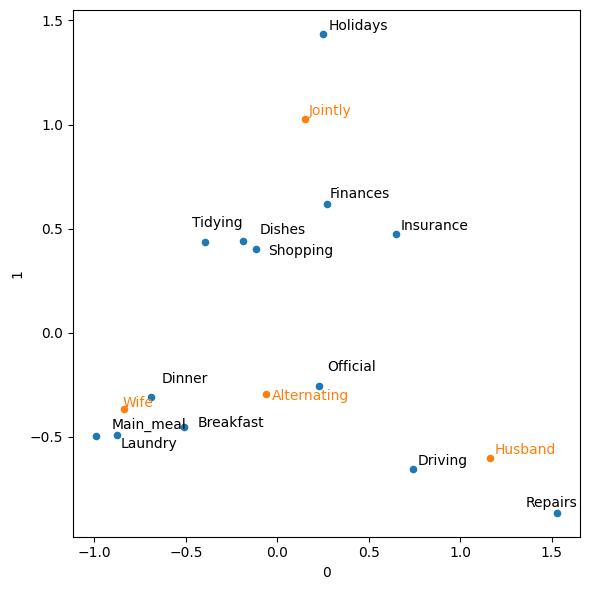

In [ ]:
housetasks = pd.read_csv(HOUSE_TASKS_CSV, index_col=0)
print(housetasks)

ca = prince.CA(n_components=2)
ca = ca.fit(housetasks)

row_coords = ca.row_coordinates(housetasks)
col_coords = ca.column_coordinates(housetasks)

# Gambar 7-4: biplot correspondence analysis (tugas = biru, pelaku = oranye)
ax = row_coords.plot.scatter(x=0, y=1, figsize=(6, 6))
col_coords.plot.scatter(x=0, y=1, ax=ax, c='C1')
texts = []
for idx, row in row_coords.iterrows():
    texts.append(plt.text(row[0], row[1], idx))
for idx, row in col_coords.iterrows():
    texts.append(plt.text(row[0], row[1], idx, color='C1'))
adjust_text(texts, only_move={'points': 'y', 'texts': 'y'})
plt.tight_layout()
plt.show()

**Interpretasi:** tugas yang berdekatan dengan sebuah pelaku pada peta **lebih sering dikerjakan oleh pelaku tersebut**. Tugas seperti *Laundry*, *Main_meal*, dan *Dinner* dekat dengan **Wife** (istri), *Repairs* dan *Driving* dekat dengan **Husband** (suami; *Driving* juga condong ke **Alternating**), sedangkan *Holidays*, *Finances*, dan *Insurance* cenderung dekat dengan **Jointly** (bersama). Peta 2D ini merangkum tabel frekuensi yang besar menjadi pola yang mudah dibaca.

### Key Ideas
- PCA mengubah variabel numerik yang **berkorelasi** menjadi **komponen utama yang tidak berkorelasi**, diurutkan menurut variansi yang dijelaskan.
- **Screeplot** menunjukkan kepentingan relatif tiap komponen dan membantu memilih jumlah komponen.
- **Loadings** menunjukkan **bagaimana tiap variabel membentuk komponen**; tanda dan besarnya dipakai untuk menafsirkan komponen.
- ***Correspondence analysis*** adalah padanan PCA untuk **data kategorikal**.

---
## 2. K-Means Clustering

**Clustering** membagi data menjadi **kelompok-kelompok** sehingga rekaman dalam satu kelompok **mirip** dan antarkelompok **berbeda**. **K-Means** adalah metode clustering paling awal dan paling banyak dipakai (Stuart Lloyd, 1957) karena **sederhana dan cepat** pada data besar.

| Istilah | Penjelasan |
|---|---|
| **Cluster** | Kelompok rekaman yang mirip |
| **Cluster mean** | Vektor rata-rata variabel untuk rekaman dalam sebuah klaster (**centroid**) |
| **K** | Jumlah klaster |

### Gagasan
K-Means membagi data menjadi $K$ klaster dengan cara **meminimalkan jumlah kuadrat jarak** tiap rekaman ke **rata-rata klasternya** (*within-cluster sum of squares*, WSS atau *inertia*):

$$\text{WSS} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \bar{x}_k \rVert^2$$

### Algoritma (Lloyd)
1. Tentukan $K$ dan **inisialisasi** $K$ pusat klaster (acak).
2. **Penugasan:** tiap rekaman dimasukkan ke klaster dengan pusat **terdekat**.
3. **Pembaruan:** hitung ulang pusat klaster sebagai **rata-rata** anggotanya.
4. Ulangi langkah 2-3 sampai penugasan **tidak berubah** (konvergen) atau mencapai batas iterasi.

Hasilnya bergantung pada inisialisasi (bisa mencapai **optimum lokal**), sehingga algoritma dijalankan **beberapa kali** dengan inisialisasi acak berbeda dan diambil hasil terbaik (`n_init` di scikit-learn). Data biasanya **dinormalisasi (distandardisasi)** dulu agar variabel berskala besar tidak mendominasi jarak.

### Contoh sederhana: XOM dan CVX

In [ ]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
kmeans = KMeans(n_clusters=4, n_init='auto', random_state=1).fit(df)
df['cluster'] = kmeans.labels_
print(df.head())

centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
print('\nPusat klaster:')
print(centers)

                 XOM       CVX  cluster
2011-01-03  0.736805  0.240681        3
2011-01-04  0.168668 -0.584516        0
2011-01-05  0.026631  0.446985        3
2011-01-06  0.248558 -0.919751        0
2011-01-07  0.337329  0.180511        3

Pusat klaster:
        XOM       CVX
0 -0.286422 -0.492965
1  1.092072  1.581077
2 -1.123045 -1.718845
3  0.325846  0.449970


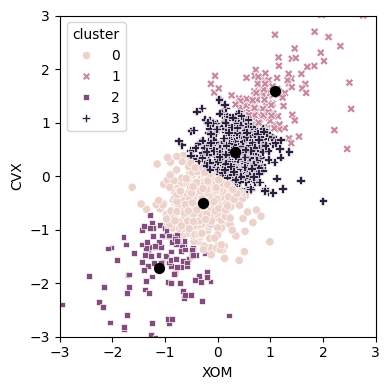

In [ ]:
# Gambar 7-5: klaster K-Means pada return XOM dan CVX
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster',
                     ax=ax, data=df)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=50, color='black')

plt.tight_layout()
plt.show()

**Interpretasi:** klaster 2 dan klaster 1 menangkap hari-hari ketika **kedua saham turun tajam** (pusat ≈ −1,1 dan −1,7) atau **naik tajam** (pusat ≈ 1,1 dan 1,6), sedangkan klaster 0 dan 3 adalah hari-hari dengan **penurunan atau kenaikan ringan** di sekitar pusat. Titik hitam adalah **pusat (rata-rata) klaster**. Perhatikan nomor klaster bersifat **sembarang** (urutannya bisa berubah antar run).

In [ ]:
# Implementasi manual algoritma Lloyd pada XOM-CVX untuk memperlihatkan langkah penugasan & pembaruan
X = df[['XOM', 'CVX']].to_numpy()
rng = np.random.default_rng(0)
pusat = X[rng.choice(len(X), 4, replace=False)]          # inisialisasi acak

for iterasi in range(1, 101):
    jarak = ((X[:, None, :] - pusat[None, :, :]) ** 2).sum(axis=2)   # jarak kuadrat ke tiap pusat
    label = jarak.argmin(axis=1)                                     # langkah penugasan
    pusat_baru = np.array([X[label == k].mean(axis=0) for k in range(4)])   # langkah pembaruan
    if np.allclose(pusat_baru, pusat):
        break
    pusat = pusat_baru

wss_manual = sum(((X[label == k] - pusat[k]) ** 2).sum() for k in range(4))
print(f'Konvergen setelah {iterasi} iterasi')
print(f'WSS manual   : {wss_manual:.2f}')
print(f'WSS sklearn  : {kmeans.inertia_:.2f}  (n_init=auto; bisa sedikit berbeda karena optimum lokal)')

Konvergen setelah 19 iterasi
WSS manual   : 408.82
WSS sklearn  : 410.50  (n_init=auto; bisa sedikit berbeda karena optimum lokal)


**Interpretasi:** implementasi manual konvergen setelah 19 iterasi dengan WSS ≈ 408,8, **sedikit lebih rendah** daripada hasil scikit-learn (≈ 410,5). Selisih ini menunjukkan bahwa K-Means hanya menjamin **optimum lokal**: inisialisasi yang berbeda dapat berakhir di solusi yang sedikit berbeda, itulah alasan algoritma dijalankan dengan beberapa inisialisasi.

### Menginterpretasi Klaster
Berikut K-Means dengan $K=5$ pada 16 saham (sejak 2011). Kita lihat **ukuran klaster** dan **pusat klaster** (rata-rata return tiap saham pada hari-hari anggota klaster).

Ukuran klaster: [(np.int32(0), 256), (np.int32(1), 271), (np.int32(2), 130), (np.int32(3), 152), (np.int32(4), 322)]


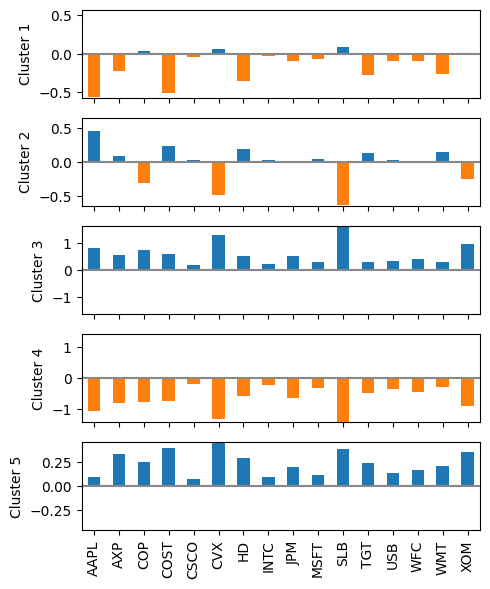

In [ ]:
kmeans = KMeans(n_clusters=5, n_init='auto', random_state=1).fit(top_sp)
print('Ukuran klaster:', sorted(Counter(kmeans.labels_).items()))

centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)

# Gambar 7-6: pusat klaster (rata-rata return tiap saham)
f, axes = plt.subplots(5, 1, figsize=(5, 6), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i + 1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

**Interpretasi:** klaster dibedakan oleh **pola gerak** pada tiap hari. Klaster 4 (152 hari) adalah hari-hari **turun serentak** dengan semua bar negatif (pasar anjlok, terutama SLB dan CVX), klaster 3 (130 hari) adalah hari-hari **naik serentak** dengan semua bar positif dan paling besar, klaster 5 (322 hari) adalah hari-hari **naik ringan**, klaster 1 (256 hari) adalah hari-hari **turun ringan** (terutama energi dan ritel), dan klaster 2 (271 hari) adalah hari-hari ketika **sektor energi turun** (SLB, CVX, XOM) sementara AAPL dan HD naik. Klaster terkecil berisi hari-hari ekstrem.

### Memilih Jumlah Klaster
K-Means mengharuskan kita menentukan $K$. Tidak ada jawaban pasti; salah satu cara adalah **elbow method**: plot rata-rata WSS per klaster terhadap $K$, lalu cari titik "siku" saat tambahan klaster tidak lagi menurunkan WSS secara berarti. Pendekatan lain: ukuran ***silhouette***, *gap statistic*, serta pertimbangan **kegunaan bisnis**.

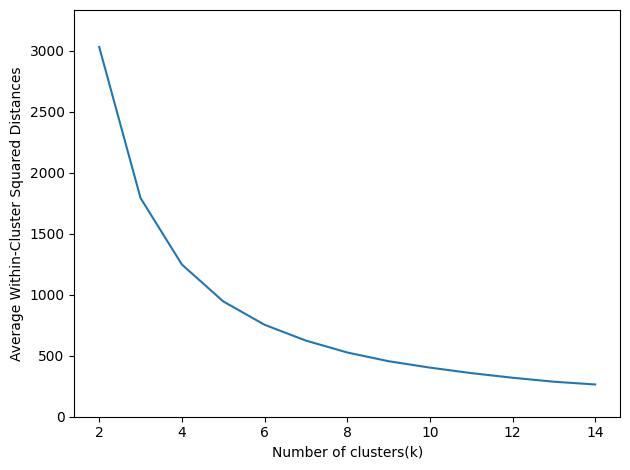

In [ ]:
# Gambar 7-7: elbow method (rata-rata WSS per klaster)
inertia = []
for n_clusters in range(2, 15):
    km = KMeans(n_clusters=n_clusters, random_state=0, n_init='auto').fit(top_sp)
    inertia.append(km.inertia_ / n_clusters)
inertias = pd.DataFrame({'n_clusters': range(2, 15), 'inertia': inertia})
ax = inertias.plot(x='n_clusters', y='inertia')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Average Within-Cluster Squared Distances')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Tidak ada di buku: ukuran silhouette sebagai pembanding elbow method (makin tinggi makin baik)
from sklearn.metrics import silhouette_score
sil = []
for k in range(2, 11):
    lab = KMeans(n_clusters=k, random_state=0, n_init='auto').fit_predict(top_sp)
    sil.append({'K': k, 'silhouette': silhouette_score(top_sp, lab)})
sil = pd.DataFrame(sil)
print(sil.round(4).to_string(index=False))
print('K dengan silhouette tertinggi:', int(sil.loc[sil.silhouette.idxmax(), 'K']))

 K  silhouette
 2      0.2233
 3      0.1552
 4      0.1219
 5      0.1081
 6      0.1010
 7      0.0983
 8      0.0921
 9      0.0866
10      0.0760
K dengan silhouette tertinggi: 2


**Interpretasi:** rata-rata WSS per klaster **menurun cepat** hingga sekitar $K=4$ sampai 6 lalu **melandai**; tidak ada "siku" yang tajam, sehingga pemilihan $K$ membutuhkan **pertimbangan praktis** (berapa klaster yang masih bermakna dan dapat ditindaklanjuti). Silhouette justru tertinggi pada $K=2$ (≈ 0,22) dan turun seiring bertambahnya $K$, jadi dua kriteria ini **tidak selalu sepakat**; data return saham memang tidak memiliki klaster yang terpisah tegas.

### Key Ideas
- Jumlah klaster $K$ **ditentukan pengguna**.
- Algoritma **berulang** memperbarui penugasan dan pusat klaster sampai konvergen.
- Hasilnya bergantung inisialisasi; jalankan beberapa kali (`n_init`), dan **standardisasi** variabel terlebih dahulu.
- Pilih $K$ dengan **elbow method**, silhouette, dan pertimbangan bisnis.

---
## 3. Hierarchical Clustering

**Hierarchical clustering** adalah alternatif K-Means yang tidak memerlukan $K$ di awal dan menghasilkan **hierarki klaster** (diagram pohon yang disebut **dendrogram**). Ia **fleksibel** dan menampilkan **struktur bertingkat** data, tetapi **jauh lebih mahal secara komputasi** sehingga cocok untuk dataset relatif kecil.

| Istilah | Penjelasan |
|---|---|
| **Dendrogram** | Representasi visual rekaman dan hierarki klaster tempat mereka bergabung |
| **Distance** | Ukuran seberapa dekat satu rekaman dengan rekaman lain |
| **Dissimilarity** | Ukuran seberapa dekat satu **klaster** dengan klaster lain |

### Algoritma agglomerative
1. Mulai dengan **setiap rekaman sebagai klaster tersendiri**.
2. Hitung **ketidakmiripan (dissimilarity)** antara semua pasangan klaster.
3. **Gabungkan** dua klaster yang paling mirip.
4. Ulangi langkah 2-3 sampai tersisa **satu klaster**.

### Contoh sederhana: mengelompokkan saham
Di sini yang diklasterkan adalah **saham** (bukan hari): tiap saham direpresentasikan oleh deret return hariannya (data ditranspos).

In [ ]:
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()

Z = linkage(df, method='complete')
print('Bentuk matriks linkage:', Z.shape, '(n-1 penggabungan x 4 kolom)')
print(pd.DataFrame(Z[:5], columns=['klaster_a', 'klaster_b', 'jarak', 'ukuran']).round(3))

Bentuk matriks linkage: (17, 4) (n-1 penggabungan x 4 kolom)
   klaster_a  klaster_b   jarak  ukuran
0       14.0       15.0   8.595     2.0
1        5.0        9.0   8.707     2.0
2       11.0       19.0  11.439     3.0
3       18.0       20.0  13.541     5.0
4       10.0       21.0  17.543     6.0


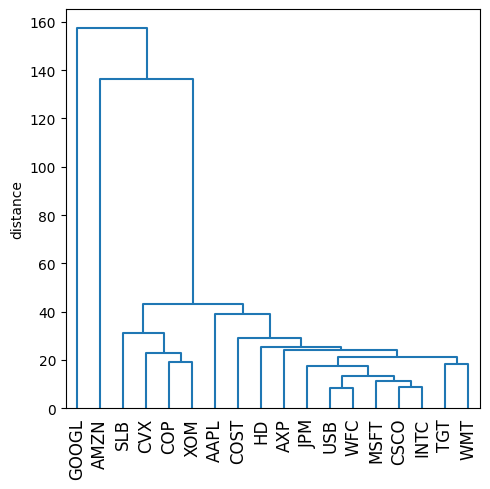

In [ ]:
# Gambar 7-8: dendrogram saham
fig, ax = plt.subplots(figsize=(5, 5))
dendrogram(Z, labels=list(df.index), color_threshold=0)
plt.xticks(rotation=90)
ax.set_ylabel('distance')

plt.tight_layout()
plt.show()

In [ ]:
# Memotong dendrogram menjadi 4 klaster
memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


**Interpretasi:** dendrogram menggabungkan terlebih dahulu **saham-saham yang paling mirip** (penggabungan pertama: USB dan WFC, lalu CSCO dan INTC), kemudian kelompok yang lebih berjauhan. **Tinggi penggabungan** = jarak antar klaster saat digabung. Saat dipotong menjadi 4 klaster, diperoleh: **energi** (COP, CVX, SLB, XOM), **satu klaster besar** berisi 12 saham lain (teknologi, keuangan, dan ritel), serta **AMZN** dan **GOOGL** yang masing-masing berdiri sendiri karena volatilitasnya jauh lebih tinggi (ingat simpangan baku GOOGL ≈ 4,2 dan AMZN ≈ 3,0). Sektor energi terpisah dengan jelas tanpa diberi label sektor; pemisahan sektor lain memerlukan pemotongan dendrogram pada ketinggian lebih rendah.

### Ukuran Ketidakmiripan (*Linkage*)
Pada langkah 2, ketidakmiripan antar **klaster** dapat didefinisikan berbeda:

| Metode | Definisi | Kecenderungan |
|---|---|---|
| **Single** | Jarak **terdekat** antara dua titik dari klaster berbeda | Klaster memanjang seperti rantai; sensitif terhadap *noise* |
| **Complete** | Jarak **terjauh** antara dua titik dari klaster berbeda | Klaster kompak berukuran seimbang |
| **Average** | **Rata-rata** semua jarak antar pasangan titik | Kompromi single dan complete |
| **Ward** | Penggabungan yang menghasilkan **kenaikan WSS terkecil** | Mirip K-Means: klaster kompak seimbang |

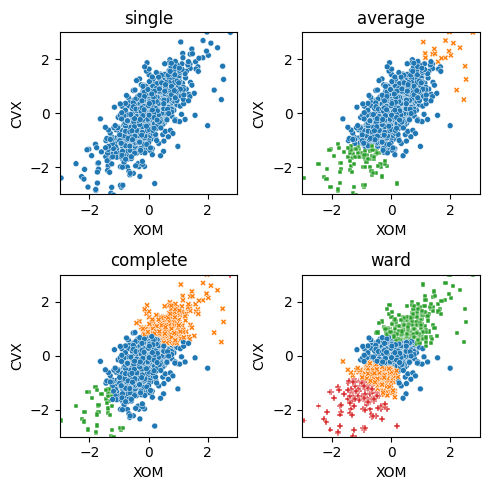

In [ ]:
# Gambar 7-9: perbandingan ukuran ketidakmiripan pada data XOM-CVX
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))
for i, method in enumerate(['single', 'average', 'complete', 'ward']):
    ax = axes[i // 2, i % 2]
    Z = linkage(df, method=method)
    colors = [f'C{c+1}' for c in fcluster(Z, 4, criterion='maxclust')]
    ax = sns.scatterplot(x='XOM', y='CVX', hue=colors, style=colors,
                         size=0.5, ax=ax, data=df, legend=False)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(method)

plt.tight_layout()
plt.show()

**Interpretasi:** metode **single** menghasilkan satu klaster raksasa dengan klaster-klaster kecil berisi titik pencilan (efek rantai). **Average** serupa (satu klaster dominan, klaster kecil di ekor), **complete** lebih seimbang, dan **ward** paling seimbang serta menyerupai hasil K-Means.

### Key Ideas
- Hierarchical clustering tidak memerlukan $K$ di awal dan menghasilkan **dendrogram** yang dapat dipotong pada ketinggian berbeda.
- Algoritma **agglomerative** menggabungkan klaster paling mirip secara berulang.
- Hasil bergantung **ukuran ketidakmiripan** (single, complete, average, ward).
- **Mahal secara komputasi**: cocok untuk data kecil sampai menengah.

---
## 4. Model-Based Clustering

K-Means dan hierarchical clustering bersifat **heuristik**. **Model-based clustering** memberi **landasan statistik formal**: data diasumsikan berasal dari **campuran (mixture) beberapa distribusi probabilitas**, masing-masing mewakili satu klaster. Pendekatan yang paling lazim adalah **campuran distribusi normal multivariat** (*Gaussian mixture model*, GMM).

| Istilah | Penjelasan |
|---|---|
| **Multivariate normal distribution** | Distribusi normal untuk beberapa variabel, ditentukan oleh **vektor mean** dan **matriks kovarians** |
| **Mixture of normals** | Campuran beberapa distribusi normal dengan **bobot** (proporsi klaster) tertentu |
| **BIC** | *Bayesian Information Criterion*: ukuran kecocokan model yang **menghukum kompleksitas** (jumlah parameter) |

### Distribusi normal multivariat
Pada dua variabel, distribusi normal multivariat dijelaskan oleh **mean** $\mu = (\mu_1, \mu_2)$ dan **matriks kovarians** $\Sigma$. Kontur kepadatannya berbentuk **elips**; kemiringan elips ditentukan oleh **korelasi** antar variabel.

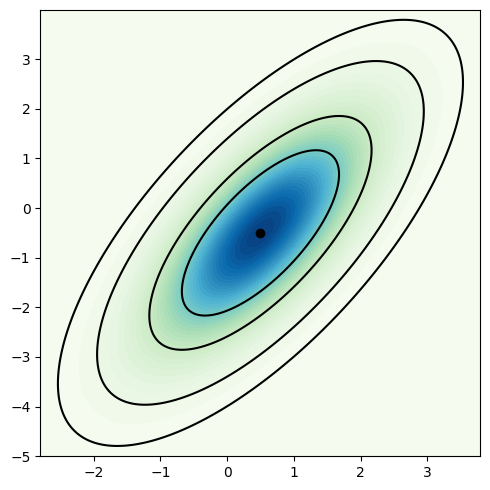

In [ ]:
# Gambar 7-10: distribusi normal multivariat dua dimensi (kontur = tingkat probabilitas 50%, 75%, 95%, 99%)
mean = [0.5, -0.5]
cov = [[1, 1], [1, 2]]
probability = [.5, .75, .95, .99]
def probLevel(p):
    D = 1
    return (1 - p) / (2 * math.pi * D)
levels = [probLevel(p) for p in probability]

fig, ax = plt.subplots(figsize=(5, 5))

x, y = np.mgrid[-2.8:3.8:.01, -5:4:.01]
pos = np.empty(x.shape + (2,))
pos[:, :, 0] = x; pos[:, :, 1] = y
rv = multivariate_normal(mean, cov)

CS = ax.contourf(x, y, rv.pdf(pos), cmap=cm.GnBu, levels=50)
ax.contour(CS, levels=levels, colors=['black'])
ax.plot(*mean, color='black', marker='o')

plt.tight_layout()
plt.show()

### Campuran Distribusi Normal (*Mixtures of Normals*)
Pada GMM dengan $K$ klaster, kepadatan data adalah

$$f(x) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k), \qquad \sum_k \pi_k = 1$$

dengan $\pi_k$ proporsi klaster ke-$k$. Parameter ($\pi_k$, $\mu_k$, $\Sigma_k$) diestimasi dengan algoritma **EM (*Expectation-Maximization*)**, versi "lunak" dari K-Means:
- **E-step:** hitung **probabilitas** tiap rekaman milik tiap klaster (penugasan *lunak*, bukan keras).
- **M-step:** perbarui parameter klaster memakai probabilitas itu sebagai bobot.

Berbeda dengan K-Means (klaster **bulat**), GMM dapat menangkap klaster **elips** berbagai bentuk dan ukuran serta menyediakan **probabilitas keanggotaan**.

BIC (2 komponen): 4589.92885731864


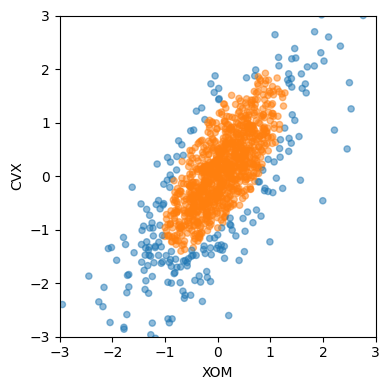

In [ ]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2, random_state=1).fit(df)
print('BIC (2 komponen):', mclust.bic(df))

# Gambar 7-11: dua klaster hasil mixture of normals
fig, ax = plt.subplots(figsize=(4, 4))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

plt.tight_layout()
plt.show()

In [ ]:
print('Bobot klaster (pi):', mclust.weights_.round(3))
print('\nMean')
print(mclust.means_)
print('\nKovarians')
print(mclust.covariances_)

Bobot klaster (pi): [0.345 0.655]

Mean
[[-0.05031426 -0.21161823]
 [ 0.07246995  0.10494619]]

Kovarians
[[[0.97123064 0.97764343]
  [0.97764343 1.67233845]]

 [[0.26822676 0.27562091]
  [0.27562091 0.51679853]]]


**Interpretasi:** klaster berbobot 65,5% memiliki **kovarians kecil** (variansi ≈ 0,27 dan 0,52: hari-hari tenang, titik padat di sekitar pusat) dan klaster berbobot 34,5% memiliki **kovarians besar** (variansi ≈ 0,97 dan 1,67: hari-hari bergejolak, sebaran luas). Pembagian ini **tidak bisa ditangkap K-Means** yang mengasumsikan klaster berbentuk bulat dan berukuran mirip. Mean kedua klaster sama-sama dekat nol; yang membedakan adalah **sebaran (volatilitas)**-nya.

### Memilih Jumlah Klaster dengan BIC
Dengan model probabilistik, kita dapat membandingkan model berbeda lewat **BIC** (makin kecil makin baik):

$$\text{BIC} = -2 \ln \hat{L} + p \ln n$$

dengan $\hat{L}$ likelihood maksimum, $p$ jumlah parameter, $n$ jumlah rekaman. Suku pertama menghargai kecocokan, suku kedua **menghukum kompleksitas**. Kita membandingkan juga **jenis matriks kovarians**: `full` (bebas tiap klaster), `tied` (sama untuk semua), `diag` (diagonal), `spherical` (bulat).

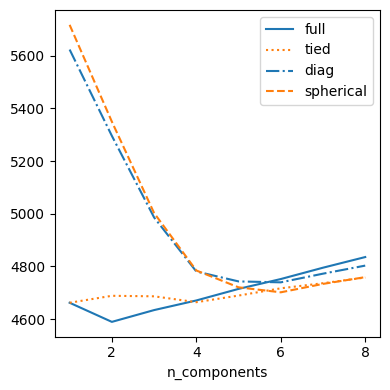

BIC terendah: 4589.9 dengan 2 komponen, kovarians 'full'


In [ ]:
# Gambar 7-12: BIC untuk berbagai jumlah klaster dan jenis kovarians
results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components=n_components, warm_start=True,
                                 covariance_type=covariance_type, random_state=1)
        mclust.fit(df)
        results.append({
            'bic': mclust.bic(df),
            'n_components': n_components,
            'covariance_type': covariance_type,
        })

results = pd.DataFrame(results)

colors = ['C0', 'C1', 'C2', 'C3']
styles = ['C0-', 'C1:', 'C0-.', 'C1--']

fig, ax = plt.subplots(figsize=(4, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type,
                kind='line', style=styles[i])

plt.tight_layout()
plt.show()

terbaik = results.loc[results.bic.idxmin()]
print(f"BIC terendah: {terbaik.bic:.1f} dengan {int(terbaik.n_components)} komponen, kovarians '{terbaik.covariance_type}'")

**Interpretasi:** BIC terendah (≈ 4.590) dicapai oleh model dengan **kovarians `full` dan 2 komponen**; menambah komponen pada `full` **menaikkan BIC** karena kompleksitasnya tidak sebanding dengan perbaikan kecocokan. Model dengan kovarians yang lebih kaku (`diag`, `spherical`) sangat buruk pada 1 sampai 3 komponen (BIC > 5.000) dan baru mendekati BIC ≈ 4.700 setelah memakai 5 sampai 6 komponen, tetapi tetap tidak mengungguli `full` dengan 2 komponen.

> **Catatan.** Model-based clustering mengasumsikan data **kira-kira normal** per klaster. Pada data yang jauh dari normal (ekor panjang, sangat miring), hasilnya bisa menyesatkan; transformasi data atau metode lain mungkin diperlukan.

### Key Ideas
- Klaster diasumsikan berasal dari **distribusi probabilitas berbeda** (umumnya normal multivariat), dengan proporsi tertentu.
- Parameter diestimasi dengan **EM**; tiap rekaman memperoleh **probabilitas** keanggotaan klaster.
- **BIC** dipakai membandingkan jumlah klaster dan jenis kovarians.
- Mampu menangkap klaster **berbentuk dan berukuran berbeda** (tidak seperti K-Means).

---
## 5. Penskalaan dan Variabel Kategorikal

Metode unsupervised memerlukan variabel yang **dapat dibandingkan**: diukur pada **skala yang sebanding** dan, untuk data campuran, ada cara mengukur jarak variabel kategorikal.

| Istilah | Penjelasan |
|---|---|
| **Scaling** | Menyesuaikan data ke rentang yang sebanding antar variabel |
| **Normalization (standardization)** | Mengurangi mean dan membagi simpangan baku |
| **Gower's distance** | Ukuran jarak untuk data **campuran** numerik dan kategorikal, skala 0 sampai 1 |

### Penskalaan Variabel
Pada K-Means pinjaman macet, variabel dengan **skala besar** seperti `annual_inc` dan `revol_bal` (puluhan ribu) akan **mendominasi jarak** dibanding `dti` atau `open_acc` (satuan/puluhan). Kita bandingkan klaster **tanpa** dan **dengan** standardisasi pada pinjaman *default*.

In [ ]:
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)
defaults = loan_data.loc[loan_data['outcome'] == 'default', ]

columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc', 'dti', 'revol_util']

df = defaults[columns]
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('TANPA standardisasi:')
print(centers.round(2))

TANPA standardisasi:
   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util   size
0   17809.76    78669.45   18933.41     11.59  17.02       62.18   7906
1   21444.32   148736.06   33152.69     12.38  13.83       63.15   1654
2   24290.91   409746.47   84710.99     13.43   8.15       60.02     88
3   10274.16    41241.21    9950.10      9.48  17.72       57.90  13023


In [ ]:
scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('DENGAN standardisasi (pusat dikembalikan ke skala asli):')
print(centers.round(2))

DENGAN standardisasi (pusat dikembalikan ke skala asli):
   loan_amnt  annual_inc  revol_bal  open_acc    dti  revol_util  size
0   13484.73    55907.99   16435.80     14.32  24.21       59.46  6244
1   25950.21   116834.14   32945.97     12.40  16.17       66.12  3670
2   10507.28    51117.99   11635.29      7.51  15.93       77.80  7397
3   10324.85    53456.82    6054.82      8.66  11.31       31.00  5360


**Interpretasi:** **tanpa** standardisasi, klaster terutama dibedakan oleh **`annual_inc` dan `revol_bal`** (variabel berskala besar); ukuran klaster sangat timpang (klaster dengan pendapatan rata-rata ≈ 410 ribu hanya berisi 88 pinjaman, sedangkan klaster terbesar berisi 13.023). **Dengan** standardisasi, semua variabel **ikut berperan**: klaster dibedakan juga oleh `dti` (11 sampai 24), `open_acc`, dan `revol_util` (31% sampai 78%), dan ukuran klaster jauh lebih seimbang (5.360 sampai 7.397, kecuali satu klaster berisi 3.670). Klaster yang lebih seimbang dan lebih beragam seperti ini biasanya lebih berguna untuk segmentasi.

### Variabel yang Mendominasi (*Dominant Variables*)
Bahkan **tanpa penskalaan eksplisit**, variabel dengan **variansi besar** akan mendominasi PCA (karena PCA mengejar variansi). Contoh: return harian 2005-sekarang, ketika **Google (GOOGL)** dan **Amazon (AMZN)** memiliki simpangan baku jauh lebih besar (harga dan volatilitas tinggi), sehingga komponen pertama dan kedua hanya menangkap kedua saham itu.

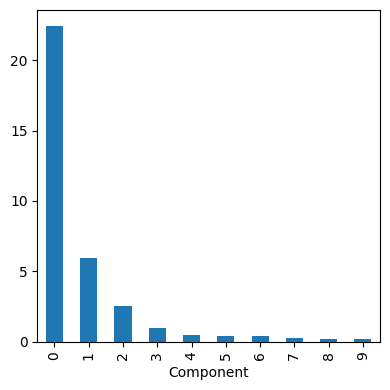

           0      1
GOOGL  0.857 -0.478
AMZN   0.445  0.874
AAPL   0.072  0.021
MSFT   0.036  0.006
CSCO   0.029  0.003
INTC   0.027  0.006
CVX    0.090  0.037
XOM    0.080  0.021
SLB    0.110  0.030
COP    0.058  0.024
JPM    0.071  0.009
WFC    0.053  0.009
USB    0.042  0.006
AXP    0.079  0.024
WMT    0.040  0.007
TGT    0.064  0.025
HD     0.051  0.033
COST   0.071  0.034

Simpangan baku return (tertinggi lebih dulu):
GOOGL    4.235
AMZN     3.012
SLB      1.254
CVX      0.952
dtype: float64


In [ ]:
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM',
        'SLB', 'COP', 'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

# Gambar 7-13 (versi screeplot): komponen pertama sangat dominan
explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()

loadings = pd.DataFrame(sp_pca1.components_[0:2, :], columns=top_sp1.columns)
print(loadings.transpose().round(3))
print('\nSimpangan baku return (tertinggi lebih dulu):')
print(top_sp1.std().sort_values(ascending=False).round(3).head(4))

**Interpretasi:** **PC1 didominasi GOOGL** (bobot 0,86) dan **PC2 didominasi AMZN** (bobot 0,87), karena variansi kedua saham ini jauh melampaui yang lain (simpangan baku 4,2 dan 3,0 vs ≤ 1,3 untuk sisanya). Dua komponen pertama menjelaskan ≈ 82% variansi, tetapi lebih mencerminkan **dua saham dominan** daripada struktur pasar yang sebenarnya. Solusinya: **standardisasi** variabel sebelum PCA (PCA pada **matriks korelasi**), atau memeriksa/menyingkirkan variabel dominan.

In [ ]:
# Tidak ada di buku: PCA setelah standardisasi -> dominasi GOOGL/AMZN hilang
top_std = pd.DataFrame(preprocessing.StandardScaler().fit_transform(top_sp1),
                       columns=top_sp1.columns)
pca_std = PCA().fit(top_std)
print('Proporsi variansi 5 komponen pertama (data distandardisasi):',
      pca_std.explained_variance_ratio_[:5].round(3))
print('Proporsi variansi 5 komponen pertama (tanpa standardisasi):',
      sp_pca1.explained_variance_ratio_[:5].round(3))
print('\nLoadings PC1 (standardisasi), 5 saham terbesar:')
print(pd.Series(pca_std.components_[0], index=top_sp1.columns).abs().sort_values(ascending=False).head(5).round(3))

Proporsi variansi 5 komponen pertama (data distandardisasi): [0.446 0.096 0.069 0.057 0.046]
Proporsi variansi 5 komponen pertama (tanpa standardisasi): [0.647 0.172 0.074 0.029 0.015]

Loadings PC1 (standardisasi), 5 saham terbesar:
JPM    0.267
AXP    0.266
WFC    0.264
USB    0.260
XOM    0.257
dtype: float64


### Data Kategorikal dan Jarak Gower
Untuk **data campuran** (numerik + kategorikal), jarak Euclidean tidak bisa dipakai langsung pada kategori. **Jarak Gower** menghitung kemiripan **per variabel** lalu merata-ratakannya:
- **Numerik:** selisih mutlak dibagi **rentang** variabel (hasilnya 0 sampai 1), $|x_i - x_j| / (\max - \min)$.
- **Kategorikal:** **0** bila kategori sama, **1** bila berbeda.

Jarak Gower keseluruhan adalah **rata-rata** jarak per variabel, sehingga berada di rentang 0 sampai 1, dan semua variabel **berkontribusi seimbang** tanpa perlu standardisasi.

> Paket standar Python (versi buku) belum menyediakan jarak Gower; fungsi berikut ditulis sendiri agar contoh Gambar 7-13 dapat direproduksi.

In [ ]:
x = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].loc[0:4, :]
print(x)

def gower_distance(data):
    # Matriks jarak Gower untuk data campuran (numerik: |xi-xj|/rentang; kategorikal: 0 jika sama, 1 jika beda)
    data = data.reset_index(drop=True)
    n_rows = len(data)
    total = np.zeros((n_rows, n_rows))
    for col in data.columns:
        v = data[col]
        if pd.api.types.is_numeric_dtype(v):
            rentang = v.max() - v.min()
            vals = v.to_numpy(dtype=float)
            d = np.abs(vals[:, None] - vals[None, :]) / (rentang if rentang > 0 else 1.0)
        else:
            vals = v.to_numpy()
            d = (vals[:, None] != vals[None, :]).astype(float)
        total += d
    return total / data.shape[1]

print('\nMatriks jarak Gower (5 pinjaman pertama):')
print(pd.DataFrame(gower_distance(x), index=x.index, columns=x.index).round(3))

     dti  payment_inc_ratio home_            purpose_
0   1.00            2.39320  RENT      major_purchase
1   5.55            4.57170   OWN      small_business
2  18.08            9.71600  RENT               other
3  10.08           12.21520  RENT  debt_consolidation
4   7.06            3.90888  RENT               other

Matriks jarak Gower (5 pinjaman pertama):
       0      1      2      3      4
0  0.000  0.622  0.686  0.633  0.377
1  0.622  0.000  0.814  0.761  0.539
2  0.686  0.814  0.000  0.431  0.309
3  0.633  0.761  0.431  0.000  0.506
4  0.377  0.539  0.309  0.506  0.000


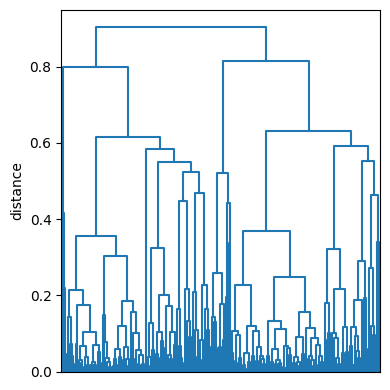

Jumlah klaster pada pemotongan jarak 0,5: 12
Ukuran klaster (5 terbesar): {9: 73, 2: 62, 3: 23, 10: 20, 11: 15}

Isi klaster nomor 11 (15 pinjaman):
       dti  payment_inc_ratio home_ purpose_
163   1.73           5.760510  RENT    other
76    9.60           0.555781  RENT    other
139  11.03           6.299230  RENT    other
20   11.54           5.302690  RENT    other
48   12.76          14.116400  RENT    other
49   15.21          11.534700  RENT    other
51   15.21           8.682500  RENT    other
99   17.22           5.227990  RENT    other
52   17.87          12.457100  RENT    other
55   19.57           2.263040  RENT    other
96   20.16           5.308270  RENT    other
75   21.10           5.723740  RENT    other
239  23.70           7.486200  RENT    other
64   24.52           6.604890  RENT    other
152  32.60          10.444200  RENT    other

Komposisi kategori pada klaster itu:
{'RENT': 15} {'other': 15}


In [ ]:
# Gambar 7-14: dendrogram jarak Gower pada sampel 250 pinjaman (dti, payment_inc_ratio, home_, purpose_)
df_g = loan_data.sample(250, random_state=301)[['dti', 'payment_inc_ratio', 'home_', 'purpose_']]
d = gower_distance(df_g)
Zg = linkage(squareform(d, checks=False), method='complete')

fig, ax = plt.subplots(figsize=(4, 4))
dendrogram(Zg, no_labels=True, color_threshold=0, ax=ax)
ax.set_ylabel('distance')
plt.tight_layout()
plt.show()

# Potong pada jarak 0,5 dan lihat isi salah satu klaster kecil
labels = fcluster(Zg, 0.5, criterion='distance')
ukuran = pd.Series(labels).value_counts()
print('Jumlah klaster pada pemotongan jarak 0,5:', len(ukuran))
print('Ukuran klaster (5 terbesar):', ukuran.head(5).to_dict())
klaster_contoh = ukuran.index[4]          # klaster terbesar ke-5 (cukup berisi untuk dilihat)
isi = df_g.reset_index(drop=True).loc[labels == klaster_contoh]
print(f'\nIsi klaster nomor {klaster_contoh} ({len(isi)} pinjaman):')
print(isi.sort_values(['home_', 'purpose_', 'dti']).to_string())
print('\nKomposisi kategori pada klaster itu:')
print(isi['home_'].value_counts().to_dict(), isi['purpose_'].value_counts().to_dict())

**Interpretasi:** dendrogram jarak Gower menunjukkan struktur bertingkat pada 250 pinjaman. Pemotongan pada jarak 0,5 menghasilkan 12 klaster (terbesar berisi 73, 62, dan 23 pinjaman). Pada klaster contoh di atas (15 pinjaman), **seluruh anggota berbagi kategori yang sama** (`home_` = RENT dan `purpose_` = other), sedangkan `dti` dan `payment_inc_ratio` masih bervariasi pada rentang menengah (mayoritas `dti` 9 sampai 25). Karena tiap variabel dinormalisasi oleh rentangnya, kategori dan angka diperlakukan setara; inilah keunggulan Gower.

### Masalah Clustering dengan Data Campuran
Alternatif umum: mengubah kategori menjadi **variabel dummy (one-hot)** lalu memakai K-Means. Namun cara ini bermasalah: setelah standardisasi, **variabel dummy ikut memengaruhi klaster dengan bobot besar**, sehingga klaster cenderung **ditentukan oleh variabel dummy** (kategori) dan bukan oleh variabel numerik.

In [ ]:
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns], dtype=int)

scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=df.columns)
centers['size'] = [int((kmeans.labels_ == i).sum()) for i in range(4)]
print(centers.round(3))

      dti  payment_inc_ratio  pub_rec_zero  home__MORTGAGE  home__OWN  \
0  21.431             12.354         0.943            -0.0       -0.0   
1  12.743              5.919         0.900            -0.0       -0.0   
2  17.340              8.354         0.906             1.0       -0.0   
3  17.198              9.267         0.918             0.0        1.0   

   home__RENT  size  
0         1.0  5363  
1         1.0  5641  
2         0.0  9779  
3         0.0  1888  


**Interpretasi:** pusat klaster menunjukkan bahwa **tiga dari empat klaster ditentukan oleh variabel dummy `home_`**: klaster 2 hanya berisi pemilik *mortgage* (`home__MORTGAGE` = 1), klaster 3 hanya pemilik rumah (`home__OWN` = 1), dan klaster 0 serta 1 hanya penyewa (`home__RENT` = 1). Klaster *mortgage* dan *own* nyaris tidak dibedakan oleh variabel numerik (`dti` 17,3 vs 17,2; `payment_inc_ratio` 8,35 vs 9,27), jadi pemisahannya **murni karena kategori**. Variabel numerik baru berperan ketika kategori sama: klaster penyewa terbelah menjadi `dti` tinggi (21,4; rasio 12,4) dan rendah (12,7; rasio 5,9). Untuk mengatasinya: beri bobot lebih kecil pada variabel dummy (mis. skalakan dummy dengan faktor < 1), pakai **jarak Gower** dengan clustering hierarkis, atau **kelompokkan per kategori** lebih dulu.

### Key Ideas
- Variabel dengan **skala/variansi besar mendominasi** K-Means dan PCA; **standardisasi** menyamakan perannya.
- **Jarak Gower** memungkinkan clustering **data campuran** numerik dan kategorikal secara seimbang.
- **One-hot encoding + K-Means** cenderung membuat klaster ditentukan oleh variabel dummy; perlu pembobotan atau metode lain.

---
## 6. Ringkasan Bab

**Unsupervised learning** mengekstrak struktur dari data tanpa variabel hasil: **PCA** mereduksi dimensi dengan komponen yang tidak berkorelasi, dan **clustering** (K-Means, hierarchical, model-based) mengelompokkan rekaman yang mirip. Keberhasilannya sangat dipengaruhi **penskalaan variabel** dan cara menangani **variabel kategorikal**; hasilnya dinilai dari **kegunaan** (apakah klaster bermakna), bukan akurasi.

| Subbab | Konsep utama | Fungsi/Metode Python |
|---|---|---|
| PCA | Komponen utama, loadings, screeplot, eigen dekomposisi | `PCA`, `.components_`, `.explained_variance_`, `np.linalg.eigh` |
| Correspondence analysis | PCA untuk data kategorikal (tabel kontingensi) | `prince.CA` |
| K-Means | Algoritma Lloyd, pusat klaster, elbow method, silhouette | `KMeans`, `.inertia_`, `silhouette_score` |
| Hierarchical clustering | Dendrogram, agglomerative, single/complete/average/ward | `linkage`, `dendrogram`, `fcluster` |
| Model-based clustering | Mixture of normals, EM, BIC | `GaussianMixture`, `.bic()`, `multivariate_normal` |
| Penskalaan & kategorikal | Standardisasi, variabel dominan, jarak Gower, masalah dummy | `StandardScaler`, `pd.get_dummies`, fungsi `gower_distance` |

### Pelajaran Penting
1. **PCA** menemukan struktur tersembunyi (mis. sektor saham) hanya dari korelasi, tanpa label.
2. **Standardisasi** wajib sebelum K-Means/PCA bila skala variabel berbeda; tanpa itu variabel besar mendominasi.
3. **K-Means** cepat tetapi mengasumsikan klaster bulat dan butuh $K$; **hierarchical** memberi struktur bertingkat tetapi mahal; **model-based** memberi probabilitas dan menangkap klaster berbentuk berbeda.
4. **Tidak ada $K$ yang "benar"**: gabungkan elbow, silhouette/BIC, dan pertimbangan bisnis.
5. Untuk **data campuran**, gunakan **jarak Gower** atau bobot dummy yang hati-hati.

---
**Referensi:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.). O'Reilly Media. Kode & data: <https://github.com/gedeck/practical-statistics-for-data-scientists>